
# Laboratorium 1: Poznaj swoje dane


W ramach naszych zajęć będziemy przechodzić przez kolejne warstwy systemu NLP:

`dane → baseline → reprezentacja → transformer → IE/NER → LLM → retrieval → RAG → ewaluacja`

Ten sam sposób myślenia będzie wracał na każdych zajęciach:

1. **pytanie badawcze,**
2. **hipoteza,**
3. **eksperyment,**
4. **metryka,**
5. **analiza błędów,**
6. **wniosek.**


> **Pytanie badawcze na dziś:** zanim wybierzemy model, czy wiemy, na jakich danych będziemy go trenować i testować?




## Po tych zajęciach student potrafi:

- wykonać podstawowy EDA dla danych tekstowych;
- sprawdzić rozkład klas i długości tekstów;
- wykryć puste rekordy, duplikaty (i potencjalne duplikaty);
- sprawdzić, czy między `train`, `validation` i `test` nie ma wycieku danych (data leakage);
- zbudować powtarzalny split i zapisać jego manifest;
- przygotować prostą kartę opisową zbioru;
- odróżnić problem modelu od problemu danych.

### Zasada na dziś

> **Podejrzanie dobry wynik jest powodem do szczegółowej ewaluacji, nie do świętowania.**



## Dane: PolEmo 2.0 / KLEJ

Pracujemy na polskich recenzjach konsumenckich z zadania [PolEmo 2.0](https://huggingface.co/datasets/allegro/klej-polemo2-in) w benchmarku KLEJ.

Klasy sentymentu:

- `plus`: pozytywny,
- `minus`: negatywny,
- `zero`: neutralny,
- `amb`: niejednoznaczny.

Repozytorium danych:  
https://huggingface.co/datasets/allegro/klej-polemo2-in

Publikacja KLEJ:  
https://arxiv.org/abs/2005.00630

Licencja zbioru na Hugging Face: CC BY-SA 4.0.

> **Ważne:** w projekcie produkcyjnym sprawdzamy nie tylko jakość danych, ale również ich pochodzenie, licencję, warunki redystrybucji i możliwość przetwarzania.



## Ustawienia wstępne

Do laboratorium wystarczy klasyczny stack Data Science.

Jeśli pracują Państwo w izolowanym / nowym środowisku:

```bash
pip install pandas numpy matplotlib scikit-learn pyarrow
```

In [82]:
from pathlib import Path
import hashlib
import json
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

RANDOM_STATE = 42

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_columns", 50)

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)


## 1. Pobranie danych

Ładujemy oficjalne splity. Podział danych jest częścią eksperymentu, a nie technicznym szczegółem.


In [83]:
# TODO: ładowanie splitów datasetu (pliki train.csv, valid.csv, test.csv w repozytorium HF)
#
# Po tej komórce MUSZĄ istnieć (używają ich dalsze komórki):
#   URLS        - dict: split -> URL pliku
#   splits      - dict: "train" / "validation-" / "test" -> DataFrame z kolumnami text, target, split
#   train_df, val_df, test_df
#   SPLIT_SIZES - dict: split -> liczba rekordów
#   CLASSES     - lista klas
#   LABEL_MAP   - dict: oryginalna etykieta -> plus / minus / zero / amb

# Uwaga: nazwy kolumn w pliku źródłowym mogą różnić się od nazw używanych w notatniku.

URLS = {
    "train": "https://huggingface.co/datasets/allegro/klej-polemo2-in/blob/main/train.csv",
    "valid": "https://huggingface.co/datasets/allegro/klej-polemo2-in/blob/main/valid.csv",
    "test": "https://huggingface.co/datasets/allegro/klej-polemo2-in/blob/main/test.csv"
}
SPLIT_SIZES = {}
NAMES = ["text", "target"]
train_df = pd.read_csv("train.csv", names=NAMES,header=0)
valid_df = pd.read_csv("valid.csv", names=NAMES, header=0)
test_df = pd.read_csv("test.csv", names=NAMES, header=0)
splits = {"train": train_df, "valid": valid_df, "test": test_df }
LABEL_MAP = {"__label__meta_plus_m": "plus", "__label__meta_minus_m": "minus", "__label__meta_zero": "zero", "__label__meta_amb": "amb"}
CLASSES = list(LABEL_MAP.values())

SPLIT_SIZES={"train": train_df.shape[0], "valid": valid_df.shape[0], "test": test_df.shape[0]}

for name, split in splits.items():
    SPLIT_SIZES[name] = split.shape[0]
    split["split"] = name
    split["target"] = split["target"].map(LABEL_MAP)

all_df = pd.concat(splits.values(), ignore_index=True)

all_df.head()

,text,target,split
0,Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą s...,plus,train
1,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wsk...,minus,train
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora...",amb,train
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie tr...",zero,train
4,Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikat...,plus,train


In [84]:
print(f"Train shape: {train_df.shape}, validation shape: {valid_df.shape}, test shape: {test_df.shape}")

Train shape: (5783, 3), validation shape: (723, 3), test shape: (722, 3)


In [85]:
train_df.columns

Index(['text', 'target', 'split'], dtype='str')


# Zadanie 1: Sanity check danych

Zanim zrobią Państwo coś bardziej zaawansowanego, proszę odpowiedzieć na pytanie:

1. Jakie kolumny zawiera zbiór?
2. Jaki jest typ każdej kolumny?
3. Czy liczba rekordów zgadza się między źródłem a tym, co faktycznie wczytaliśmy?
4. Czy występują wartości brakujące?
5. Czy etykiety mają ten sam zbiór wartości w każdym splicie? Jeśli nazwy etykiet są nieczytelne, proszę zdefiniować `LABEL_MAP` (np. `__label__meta_plus_m` → `plus`) i zapisać go w manifeście.
6. Czy są rekordy z pustym albo bardzo krótkim tekstem?

### Do wykonania

Proszę uzupełnić komórkę poniżej. Wynik powinien zawierać jedną małą tabelę ewaluacyjną per split.


In [86]:
# TODO: sanity check dla train / validation / test.
#
# Minimalne kolumny tabeli:
# - split
# - rows
# - columns
# - missing_text
# - missing_target
# - unique_labels
#
# Wskazówka:
# display(df.isna().sum())
# display(df["target"].value_counts(dropna=False))

SHORT_WORD_THRESHOLD = 20
audit_rows = []

# MIEJSCE NA KOD
for name, split in splits.items():
    audit_rows.append({
        "split": name,
        "rows": split.shape[0],
        "columns": split.shape[1],
        "missing_text": int(split["text"].isna().sum()),
        "missing_target": int(split["target"].isna().sum()),
        "unique_labels": int(split["target"].nunique()),
        "short_texts_counter": int((split["text"].str.len() < SHORT_WORD_THRESHOLD).sum())
    })

pd.DataFrame(audit_rows)

,split,rows,columns,missing_text,missing_target,unique_labels,short_texts_counter
0,train,5783,3,0,0,4,1
1,valid,723,3,0,0,4,0
2,test,722,3,0,0,4,0


In [87]:
print(train_df[train_df["text"].str.len() < SHORT_WORD_THRESHOLD])

     text target  split
4476    P    amb  train


> 1. Zbiór zawiera 2 kolumny tj. **text** -> opinia użytkownika oraz **target** -> przyporządkowana klasa do opini dodatkowo dodałem kolumnę **split** informacja czy jest to opinia ze zbioru treningowego, walidacyjnego czy testowego.
> 2. Każda z kolumn jest typu `str`
> 3. Tak, liczba wczytanych rekordów zgadza się z liczbą zadeklarowaną w karcie zbioru.
> 4. Nie, w żadnym splicie nie ma ani jednej wartości pustej lub brakującej w obu kolumnach.
> 5. Tak, w każdym splicie etykiety przyjmuja następujące wartości ['minus', 'plus', 'zero', 'amb'], są to etykiety otrzymane po przez zmapowania oryginalnych według **LABEL_MAP**
> 6. Tak, w zbiorze treningowym jest jedna opinia `P`, która została przyporządkowana do klasy `amb`


## Hipoteza 1

Czy dane są zbalansowane?

Zanim sporządzą Państwo wykres, proszę sformułować hipotezę.

> Spodziewam się, że __minus__ będzie klasą dominującą, ponieważ __z moich własnych obserwacji wynika, że osoby sfrustrowane cześciej piszą opinie__.


# Zadanie 2: Rozkład klas

Proszę policzyć:

- liczebność klas,
- udział procentowy klas,
- rozkład osobno dla `train`, `validation`, `test`.

Następnie proszę odpowiedzieć:

1. Czy accuracy będzie wystarczającą metryką na późniejszych zajęciach?
2. Jaki wynik osiągnąłby naiwny klasyfikator zawsze wybierający najczęstszą klasę?
3. Czy rozkłady klas między splitami są podobne?


In [88]:
# TODO: tabela rozkładu klas dla każdego splitu
def get_class_distribution(splits, classes):
    class_distribution = []
    for name, split in splits:
        total_split_size = split.shape[0] 
        for target_class in classes:
            class_size = split.loc[split["target"] == target_class].shape[0]
            class_distribution.append({
                "df_name": name,
                "target_class": target_class,
                "size": class_size,
                "percentage_per_split": round((class_size / total_split_size) * 100, 2)
            })
    return class_distribution

class_distribution_df = pd.DataFrame(get_class_distribution(splits.items(), CLASSES))
class_distribution_df

,df_name,target_class,size,percentage_per_split
0,train,plus,1568,27.11
1,train,minus,2194,37.94
2,train,zero,971,16.79
3,train,amb,1050,18.16
4,valid,plus,209,28.91
5,valid,minus,271,37.48
6,valid,zero,127,17.57
7,valid,amb,116,16.04
8,test,plus,197,27.29
9,test,minus,300,41.55


In [89]:
def display_class_distribution(df, size, title):
    pivot = df.pivot(index="df_name", columns="target_class", values=size).fillna(0)

    data = pivot.values.astype(float)
    data_cum = data.cumsum(axis=1)

    _, ax = plt.subplots(figsize=(10, 5))

    for i, (colname, color) in enumerate(zip(pivot.columns, ['skyblue', 'tomato', 'chartreuse',  'orange'])):
        widths = data[:, i]
        starts = data_cum[:, i] - widths
        rects = ax.barh(pivot.index, widths, left=starts, height=0.5, label=colname, color=color)

        ax.bar_label(rects, label_type='center')

    ax.legend(ncols=len(pivot.columns), bbox_to_anchor=(0.68, 0.9), loc='lower left', fontsize='small')
    plt.title(title)
    plt.show()

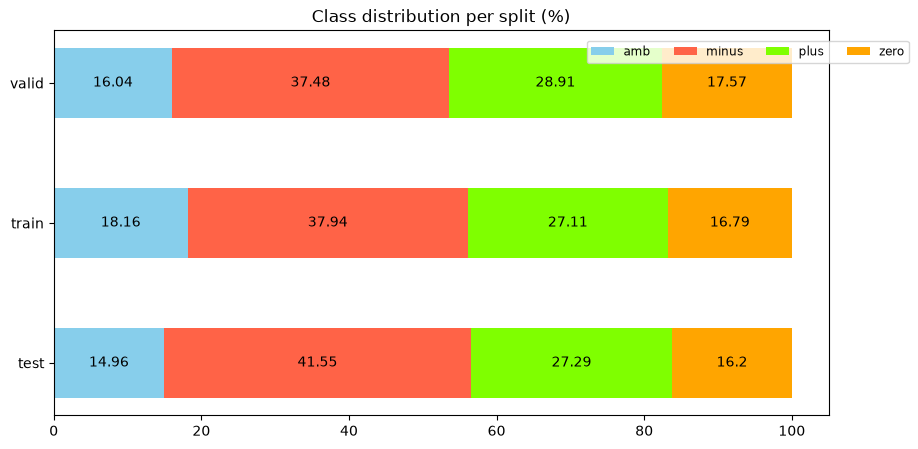

In [90]:
# TODO: wykres rozkładu klas
display_class_distribution(class_distribution_df, "percentage_per_split", "Class distribution per split (%)")

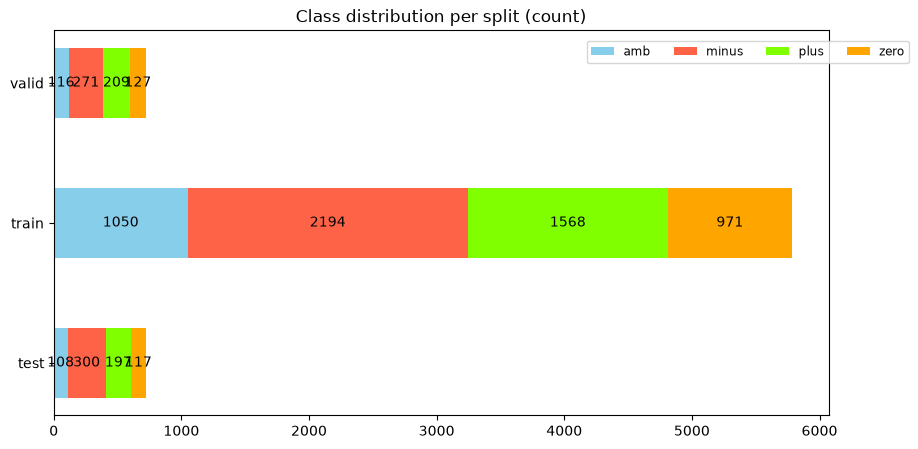

In [91]:
display_class_distribution(class_distribution_df, "size", "Class distribution per split (count)")

> 1. Nie, mamy tutaj klasy, które nie są zbalansowane, więc zastosowanie tylko i wyłącznie `accuracy` mogłoby spowodować, że przydzielanie każdej opinii do klasy `minus`. Przy takim rozkładzie klas lepiej zastosować inne metryki, np. f1-score.
> 2. Naiwny klasyfikator zawsze wybierający najczęstszą klasę (**minus**) osiągnąłby dokładność równą jej udziałowi w danym splicie: ok. 37,9% na zbiorze treningowym, ok. 37,5% na walidacyjnym oraz ok. 41,6% na testowym.
> 3. Tak, w każdym splicie rozkład klas jest zachowany proporcjonalnie i podobny.


# Zadanie 3: Jak wygląda „typowy tekst”?

Długość tekstu jest jednym z pierwszych parametrów, które warto sprawdzić.

Dp wyświetlania tekstu proszę dodać cechy:

- `n_chars`: liczba znaków,
- `n_words`: liczba słów (regex `\w+`) oraz `n_words_split` (`split()` po białych znakach),
- `n_lines`: liczba linii.

Proszę policzyć co najmniej:

- minimum,
- medianę,
- średnią,
- 90. percentyl,
- 95. percentyl,
- 99. percentyl,
- maksimum.

Następnie proszę obejrzeć (i zanotować wnioski z obserwacji):

- 5 najkrótszych tekstów,
- 5 najdłuższych tekstów.

### Pytania

- Czy ekstremalnie długi dokument zawsze jest błędem?
- Co długość dokumentów może później zmienić w tokenizacji, batchowaniu i chunkingu?
- Dlaczego `n_words_split` ≠ `n_words`? Co to mówi o przygotowaniu tekstów w tym zbiorze i jak może wpłynąć na tokenizatory w kolejnych labach?

In [92]:
# TODO: do dodania n_chars, n_words, n_words_split, n_lines.
text_stats = {'n_chars': []}
text_stats['n_chars'] = all_df['text'].apply(len)
text_stats['n_words'] = all_df['text'].str.findall(r"\w+").str.len()
text_stats['n_words_split'] = all_df['text'].str.split().str.len()
text_stats['n_lines'] = all_df['text'].str.split('\n').str.len()

text_stats_summary = []

for key in text_stats.keys():
    text_stats_summary.append({
        'name': key,
        'min': np.min(text_stats[key]),
        'average': round(np.average(text_stats[key]), 2),
        'median': text_stats[key].median(),
        'p_90': np.percentile(text_stats[key], 90),
        'p_95': np.percentile(text_stats[key], 95),
        'p_99': np.percentile(text_stats[key], 99),
        'max': np.max(text_stats[key]),
    })


In [93]:
# TODO: tabela statystyk długości
text_stats_summary_df = pd.DataFrame(text_stats_summary)
text_stats_summary_df

,name,min,average,median,p_90,p_95,p_99,max
0,n_chars,1,777.01,696.0,1294.0,1605.65,2335.19,5391
1,n_words,1,114.32,102.0,191.0,242.00,352.73,774
2,n_words_split,1,136.32,121.0,228.0,288.65,414.73,987
3,n_lines,1,1.00,1.0,1.0,1.00,1.00,1


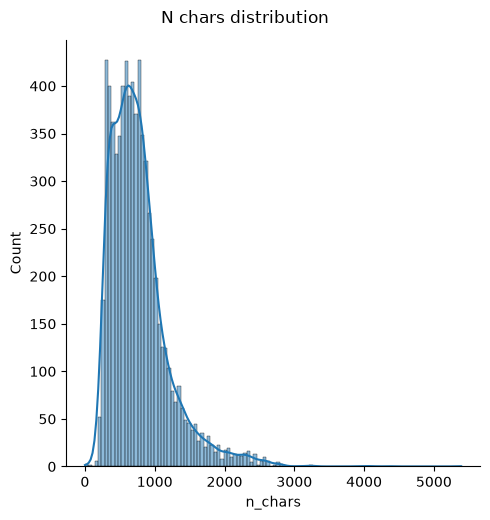

In [94]:
# TODO: histogram długości tekstów
import seaborn as sns
text_stats_summary_df = pd.DataFrame(text_stats)

g = sns.displot(data=text_stats_summary_df, x="n_chars", kde=True)
g.fig.suptitle("N chars distribution", y=1.03)

plt.show()

In [95]:
sorted_all = all_df['text'].sort_values(key=lambda x: x.str.len())
longest_5 = sorted_all[-5:]
shortest_5 = sorted_all[:5]

print("--- 5 SHORTEST ---")
for idx in shortest_5.index:
    text = all_df.loc[idx, 'text']
    print(f"Długość: {len(text)} | {text}")

print("\n------------------------------------\n")

print("--- 5 LONGEST ---")
for idx in longest_5.index:
    text = all_df.loc[idx, 'text']
    print(f"Length: {len(text)} | {text}")

--- 5 SHORTEST ---
Długość: 1 | P
Długość: 29 | Marka Baccarat Hotels & Res o
Długość: 47 | Hotel , jak za tą kwotę ( 230 - 2 osoby & aut o
Długość: 51 | W grudniu czterogwiazdkowy Hotel Korona Spa & Wel l
Długość: 78 | Hotel powinien nazywać się MARNIOR ( z uwagi na kiepska jakosc uslug ) & Gwa r

------------------------------------

--- 5 LONGEST ---
Length: 3917 | Ten Hotel to jest kpina z klienta . Hotel jedynie ładnie wygląda na zdjęciach i z daleka . Zdjęcia były robione dawno temu jak powstał ten hotel i nie aktualizowane do tej pory . Wystarczy tylko wejść do środka i czar pryska . Wszechobecny syf , obsługa w recepcji zachowująca się jakby nie wiedziała co tam robi , zimna woda i brak ogrzewania w pokojach to tylko niektóre z rzeczy które mnie osłabiły . Obsługa w recepcji nie ma pojęcia gdzie są pokoje przez co od razu na początek zwiedzili śmy cały hotel w poszukiwaniu pokoju , który znajdował się na drugim końcu budynku . Korytarze są ciemne , tapeta odpadała ze ścian i wy

> 1. Oczywście, że nie. Najczęściej, co widać powyżej długa opinia świadczy o niezadowoleniu klienta z danej usługi.
> 2. Wpływ długości opini na tokenizację, batchowanie i chunking?
>    - 2.1. **Tokenizacja:** Zbyt długie opinie mogłyby przekroczyć maksymalne ograniczenie kontekstu modelu.
>    - 2.2. **Batchowanie:** Ekstremalnie długie sekwencje drastycznie zwiększają zużycie pamięci (VRAM) podczas przetwarzania batcha.
>    - 2.3. **Chunking:** Decydujemy, czy dzielić dokument na mniejsze fragmenty, czy odrzucać nadmiar tekstu, co może rzutować na utratę kontekstu wypowiedzi i pogorszenie jakości odpowiedzi.
> 3. Różnica wynika z metody liczenia: `n_words_split` dzieli tekst po prostu po spacjach, przez co traktuje słowa wraz z interpunkcją jako jedną całość. Z kolei `n_words` używa wyrażenia regularnego, które pomija znaki interpunkcyjne. Pokazuje to, że teksty nie przeszły jeszcze dokładnego, wstępnego oczyszczania. W kolejnych labach może to sprawić, że tokenizator wygenerują zbyt wiele nietypowych tokenów przez znaki specjalne, co może obniżyć jakoś modelu.


# Zadanie 4: Szum danych

Tekst naturalny nie jest sterylny.

Proszę sprawdzić, ile rekordów zawiera co najmniej jeden z poniższych elementów:

- URL,
- adres e-mail,
- sekwencję wielu wykrzykników lub znaków zapytania,
- dużo WIELKICH LITER,
- znaki nowej linii,
- tekst krótszy niż 20 znaków.

Proszę nie usuwać ich automatycznie!

> Najpierw wykrywamy zjawisko. Potem decydujemy, czy jest błędem, sygnałem czy częścią danych.

Proszę też sprawdzić, czy którakolwiek flaga szumu jest skorelowana z etykietą. Czy to sygnał, artefakt, czy shortcut?

In [96]:
# TODO: proszę obliczyć poniższe flagi bool
#
# has_url, has_email, has_punct_burst, has_newline, is_very_short, high_uppercase
#
# Proponowany próg high_uppercase: uppercase_ratio > 0.5,
# zaleca się eksperyment z tym progiem.
#
# UWAGA: w tym zbiorze interpunkcja jest oddzielona spacjami (np. "! ! !"),
# więc prosty wzorzec [!?]{2,} jej nie wykryje.

url_regex = r'https?://\S+|www\.\S+'
email_regex = r'\S+@\S+\.\S+'
punct_burst_regex = r'[!?]\s*[!?]'
uppercase_regex = r'[A-ZĄĆĘŁŃÓŚŹŻ]'

has_url = all_df['text'].str.contains(url_regex, na=False)
has_email = all_df['text'].str.contains(email_regex, na=False)
has_punct_burst = all_df['text'].str.contains(punct_burst_regex, na=False)
has_newline = all_df['text'].str.contains('\n')
is_very_short = (all_df['text'].str.len() < 20)
uppercase_letters = (all_df['text'].str.findall(uppercase_regex).str.len() / all_df['text'].str.len() > 0.5)

print(f'Has url sum: {has_url.sum()}')
print(f'Has email sum: {has_email.sum()}')
print(f'Has punct burtst sum: {has_punct_burst.sum()}')
print(f'Is very short rows: {is_very_short.sum()}')
print(f'Has new line sum: {has_newline.sum()}')
print(f'Uppercase letters rows: {uppercase_letters.sum()}')

Has url sum: 9
Has email sum: 0
Has punct burtst sum: 808
Is very short rows: 1
Has new line sum: 0
Uppercase letters rows: 10


In [124]:
noise_flags = pd.DataFrame({
    "has_url": has_url,
    "has_email": has_email,
    "has_punct_burst": has_punct_burst,
    "has_newline": has_newline,
    "is_very_short": is_very_short,
    "high_uppercase": uppercase_letters,
}, index=all_df.index)

data = pd.concat([all_df["target"], noise_flags], axis=1).dropna(subset=["target"])

flag_totals = noise_flags.sum().rename("flagged").reset_index()
flag_totals.columns = ["flag", "flagged"]
flag_totals["n"] = len(data)
flag_totals["percent_flagged"] = (flag_totals["flagged"] / flag_totals["n"] * 100).round(1)

rates_by_label = []

for flag in noise_flags.columns:
    rates = data.groupby("target", observed=True)[flag].agg(["sum", "count", "mean"])

    for label, row in rates.iterrows():
        rates_by_label.append({
            "flag": flag,
            "target": label,
            "flagged": int(row["sum"]),
            "n": int(row["count"]),
            "percent_flagged": round(row["mean"] * 100, 1),
        })

rates_by_label = pd.DataFrame(rates_by_label)

display(rates_by_label)

,flag,target,flagged,n,percent_flagged
0,has_url,amb,0,1274,0.0
1,has_url,minus,1,2765,0.0
2,has_url,plus,1,1974,0.1
3,has_url,zero,7,1215,0.6
4,has_email,amb,0,1274,0.0
5,has_email,minus,0,2765,0.0
6,has_email,plus,0,1974,0.0
7,has_email,zero,0,1215,0.0
8,has_punct_burst,amb,88,1274,6.9
9,has_punct_burst,minus,541,2765,19.6


> Widzimy tutaj duże skolerowanie między `has_punct_burst` a klasą `minus`


# Zadanie 5: Duplikaty

Duplikat w danych treningowych nie zawsze jest problemem. Jednak duplikat między zbiorami train i test może zafałszować wyniki.

Zaczniemy od dwóch wersji tekstu:

1. `text_raw`: oryginał,
2. `text_norm`: wersja używana wyłącznie do oceny duplikatów.

Normalizacja:

- Unicode NFKC,
- lowercase,
- redukcja białych znaków,
- trim.

> Nie usuwamy interpunkcji i nie robimy agresywnego preprocessingu.


In [97]:
# TODO:
# preprocessing

# TODO:
# 1. jakie dokładne duplikaty text_raw,
# 2. jakie duplikaty text_norm,
# 3. 10 przykładowych grup duplikatów,
# 4. czy ten sam text_norm występuje w więcej niż jednym splicie?

# MIEJSCE NA KOD


def normalize_text(text):
    text = unicodedata.normalize('NFKC', text).lower()
    return re.sub(r'\s+', ' ', text).strip()

all_df['text_raw'] = all_df['text']
all_df['text_norm'] = all_df['text'].apply(normalize_text)

for split_name in ['train', 'valid', 'test']:
    split_subset = all_df[all_df['split'] == split_name]
    raw_dups = split_subset['text_raw'].duplicated().sum()
    norm_dups = split_subset['text_norm'].duplicated().sum()
    print(f"[{split_name.upper()}] Inner split -> raw: {raw_dups}, norm: {norm_dups}")

print("-" * 50)

print("Examples of duplicate groups (text_norm):")
duplicated_groups = (
    all_df.groupby('text_norm')
    .filter(lambda x: len(x) > 1)
    .groupby('text_norm')
    .agg(
        count=('text', 'count'),
        splits=('split', lambda x: sorted(x.unique().tolist()))
    )
    .sort_values('count', ascending=False)
    .head(10)
)
print(duplicated_groups)


[TRAIN] Inner split -> raw: 0, norm: 0
[VALID] Inner split -> raw: 0, norm: 0
[TEST] Inner split -> raw: 0, norm: 0
--------------------------------------------------
Examples of duplicate groups (text_norm):
Empty DataFrame
Columns: [count, splits]
Index: []



## Funkcja `audit_split_leakage`

Proszę napisać funkcję:

```python
audit_split_leakage(df, text_col="text_norm", split_col="split")
```

która zwróci rekordy występujące w więcej niż jednym splicie.

W wyniku chcemy co najmniej:

- tekst / fingerprint,
- liczbę wystąpień,
- listę splitów,
- etykiety.

To będzie pierwszy element naszej semestralnej biblioteki ewaluacyjnej.

In [98]:
def audit_split_leakage(df, text_col="text_norm", split_col="split", label_col = "target"):
    leakage_mask =  df.groupby(text_col)[split_col].transform('nunique') > 1

    return (
        df[leakage_mask].groupby(text_col)
        .agg(
            count = (split_col, 'count'),
            splits = (split_col, lambda x: sorted(x.unique().tolist())),
            lables = (label_col, lambda x: sorted(x.unique().tolist()))
        )
        .sort_values('count', ascending = False)
    )

print(audit_split_leakage(all_df))

Empty DataFrame
Columns: [count, splits, lables]
Index: []


> Jak widzimy, żadna opinia nie jest powielona ani wewnątrz splitu, ani pomiędzy nimi.


# Zadanie 6: Prawie duplikaty

Exact match nie wystarczy.

Przykład:

- `Świetny hotel. Polecam!`
- `Świetny hotel - polecam!!!`

Dla człowieka to prawie ten sam tekst. Hash ich nie połączy.

Na próbce danych proszę zbudować prosty detektor zdań, które są prawie duplikatami:

1. `TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))`,
2. `NearestNeighbors(metric="cosine")`,
3. dla każdego tekstu proszę znaleźć najbliższego **innego** sąsiada (uwaga: przy `n_neighbors=1` sąsiadem jest zwykle ten sam dokument, więc pobierz kilku i pomiń siebie),
4. proszę policzyć podobieństwo jako `1 - cosine_distance`,
5. proszę policzyć pary z podobieństwem np. `>= 0.90`, osobno w obrębie jednego splitu i między splitami.

### Nie chodzi o idealny deduplikator

Celem jest zobaczenie, że decyzja "duplikat / nie duplikat" sama może być problemem modelowym.

In [99]:
# TODO nearest_other_neighbour
N_NEIGHBORS = 2
SIMILARITY_THRESHOLD = 0.90

vectorizer = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))

X = vectorizer.fit_transform(all_df['text_norm'])

def nearest_other_neighbor(X):
    knn = NearestNeighbors(metric="cosine")
    knn.fit(X)

    distances, indices = knn.kneighbors(X, n_neighbors=N_NEIGHBORS)
    j = indices[ :, 1]
    sim = 1 - distances[: , 1]
    return j, sim
    

# MIEJSCE NA KOD
j, sim = nearest_other_neighbor(X)

In [100]:
def find_pairs(df, j, sim, threshold_min = SIMILARITY_THRESHOLD, threshold_max = 100):
    pairs = pd.DataFrame({
        "i": range(len(df)),
        "j": j,
        "sim": sim
    })

    pairs = pairs[(pairs["sim"] >=  threshold_min) & (pairs["sim"] <= threshold_max)]
    pairs = pairs[pairs["i"] < pairs["j"]]

    pairs["cross_split"] = df["split"].values[pairs["i"]] != df["split"].values[pairs["j"]]
    pairs["i_text"] = df["text"].values[pairs["i"]]
    pairs["j_text"] = df["text"].values[pairs["j"]]

    return pairs

In [101]:
pairs = find_pairs(all_df, j, sim)
pairs

,i,j,sim,cross_split,i_text,j_text
1344,1344,6642,0.999948,True,"„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i H...","„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i H..."
3413,3413,5612,0.962757,False,"Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejedneg...","Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejedneg..."
3572,3572,4360,0.943419,False,"Wracając jednak do grupy hoteli dysponujących więcej niż tysiącem pokoi , na 9 pozycji znalazły się hotele należące do Wojskowej Agencji Mieszkaniowej . Gru...","Grupa , która przez chwilę promowała się pod mało rozwojową nazwą Hotele 21 ( miało być 21 obiektów , a nawet – wliczając np . niezrealizowany projekt hotel..."


> Niestety widzimy tutaj, że mamy 3 opinie, które są bardzo podobne do innych. Dodatkowo jedna para z tych podobieństw występuje pomiędzy splitami.


# Zadanie 7: Czy split jest częścią danych?

Proszę porównać:

### A. oficjalny split
`train / validation / test`

### B. naiwny random split
po połączeniu wszystkich rekordów:

```python
train_test_split(..., stratify=target, random_state=42)
```

Nie trenujemy jeszcze modelu docelowego. Chcemy zobaczyć, czy sam sposób dzielenia danych może zmienić eksperyment.

Proszę sprawdzić dla obu wariantów:

- rozkład klas,
- exact duplicates między train/test,
- near-duplicates, jeśli masz czas.

### Pytanie

Czy losowy split jest zawsze metodologicznie poprawny?

Proszę pomyśleć o:

- użytkownikach,
- autorach,
- czasie,
- źródłach,
- dokumentach należących do tej samej sprawy,
- wielu fragmentach pochodzących z jednego dokumentu.


In [102]:
# MIEJSCE NA KOD
from sklearn.model_selection import train_test_split

X_train_rnd, X_test_rnd = train_test_split(all_df, test_size=0.2, stratify=all_df["target"])
X_test_rnd, X_val_rnd = train_test_split(X_test_rnd, test_size=0.5, stratify=X_test_rnd["target"])

X_train_rnd["split"] = "train"
X_val_rnd["split"] = "val"
X_test_rnd["split"] = "test"

all_rnd_df = pd.concat([X_train_rnd, X_val_rnd, X_test_rnd], ignore_index=True)

print(f"Train: {X_train_rnd.shape}, test: {X_test_rnd.shape}, val: {X_val_rnd.shape}")

Train: (5782, 5), test: (723, 5), val: (723, 5)


In [103]:
# MIEJSCE NA KOD
splits_rnd =  zip(["train", "test", "val"], [X_train_rnd, X_test_rnd, X_val_rnd])
class_distribution_rnd_df = pd.DataFrame(get_class_distribution(splits_rnd, CLASSES))
class_distribution_rnd_df

,df_name,target_class,size,percentage_per_split
0,train,plus,1579,27.31
1,train,minus,2212,38.26
2,train,zero,972,16.81
3,train,amb,1019,17.62
4,test,plus,197,27.25
5,test,minus,276,38.17
6,test,zero,122,16.87
7,test,amb,128,17.70
8,val,plus,198,27.39
9,val,minus,277,38.31


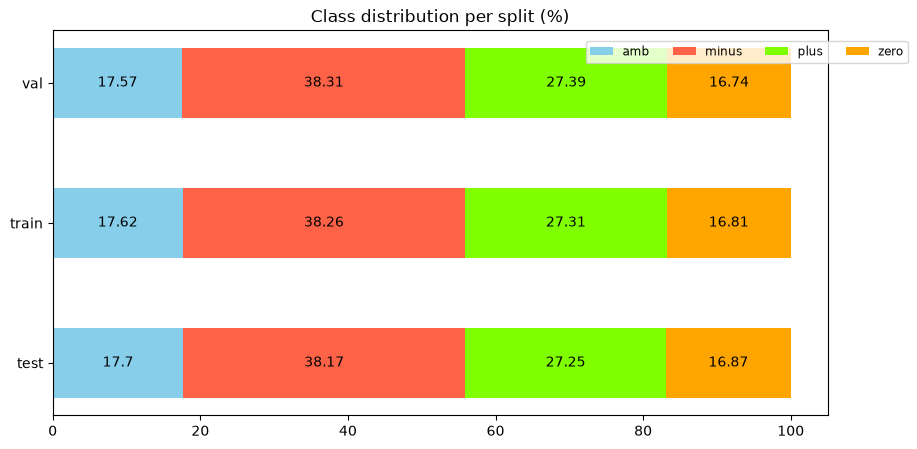

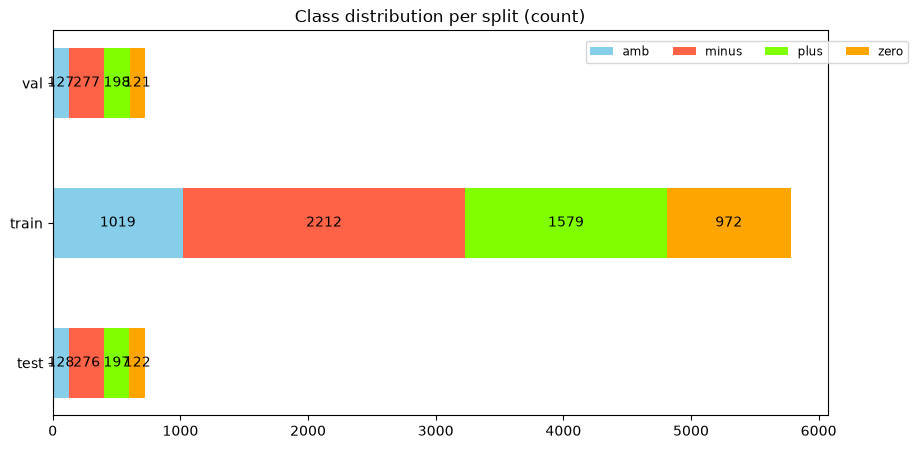

In [104]:
display_class_distribution(class_distribution_rnd_df, "percentage_per_split", "Class distribution per split (%)")
display_class_distribution(class_distribution_rnd_df, "size", "Class distribution per split (count)")

> Q: Czy losowy split jest zawsze metodologicznie poprawny?
> A: Oczywiście, że nie. Istnieje wiele czynników strukturalnych, przez które losowy podział prowadzi do wycieku danych (data leakage) i optymistycznie zafałszowanych wyników. Przykłady takich problemów to:
> - **Użytkownicy i Autorzy:** Jeśli w zbiorze mamy wiele wpisów od tych samych osób, losowy split rozdzieli je pomiędzy trening a test. Model nie uczy się wtedy ogólnego wzorca, tylko „zapamiętuje” specyficzny styl pisania użytkownika.
> - **Czas (Time-based splitting):** W danych uporządkowanych w czasie losowy podział powoduje tzw. wyciek z przyszłości (model uczy się na danych późniejszych, aby przewidywać wcześniejsze, co w rzeczywistości jest niemożliwe).
> - **Źródła i Dokumenty powiązane:** Dokumenty pochodzące z tego samego źródła czy tej samej książki są silnie skorelowane. Losowanie sprawia, że niemal identyczne fragmenty trafiają do obu zbiorów, drastycznie fałszując metryki ewaluacji.

In [105]:
test_train_norm_duplicated_rnd = set(X_train_rnd["text_norm"]).intersection(set(X_test_rnd["text_norm"]))
test_train_norm_duplicated_rnd

set()

In [106]:
# MIEJSCE NA KOD
vectorizer_rnd = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5))
X_rnd = vectorizer_rnd.fit_transform(all_rnd_df['text_norm'])

j_rnd, sim_rnd = nearest_other_neighbor(X_rnd)
pairs_rnd = find_pairs(all_rnd_df, j_rnd, sim_rnd)
pairs_rnd

,i,j,sim,cross_split,i_text,j_text
2650,2650,4660,0.999948,False,"„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i H...","„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i H..."
3257,3257,6298,0.962757,True,"Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejedneg...","Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejedneg..."
3773,3773,5856,0.943419,True,"Grupa , która przez chwilę promowała się pod mało rozwojową nazwą Hotele 21 ( miało być 21 obiektów , a nawet – wliczając np . niezrealizowany projekt hotel...","Wracając jednak do grupy hoteli dysponujących więcej niż tysiącem pokoi , na 9 pozycji znalazły się hotele należące do Wojskowej Agencji Mieszkaniowej . Gru..."


> Podobnie jak na danych oryginalnie podzielonych, brak tutaj bezpośrednich duplikatów. Jednak ponownie widzimy 3 pary opinii do siebie bardzo zbliżonych.


# Zadanie 8: Eksperyment: wyciek danych potrafi „ulepszyć” model

Teraz użyjemy bardzo prostego klasyfikatora wyłącznie jako sondy diagnostycznej. Nie optymalizujemy hiperparametrów. To będzie temat kolejnego laboratorium.

Pipeline:

`TF-IDF → Logistic Regression`

Najpierw policzymy wynik na poprawnym splicie, a potem celowo zanieczyścimy train przykładami z testu.

### Hipoteza

Proszę sformułować przed uruchomieniem założenie:

> Jak zmieni się accuracy / macro-F1 po wprowadzeniu leakage i dlaczego?


> Obie metryki będą rosły wraz ze wzrostem wycieku. Dzieje się tak, ponieważ model zobaczy dane dwukrotnie: raz w treningu i raz w predykcji, co sztucznie poprawi ich jakość.

In [107]:

probe = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=50_000,
        sublinear_tf=True,
    )),
    ("clf", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])

def evaluate_probe(train_part: pd.DataFrame, test_part: pd.DataFrame):
    probe.fit(train_part["text"], train_part["target"])
    pred = probe.predict(test_part["text"])
    return {
        "accuracy": accuracy_score(test_part["target"], pred),
        "macro_f1": f1_score(test_part["target"], pred, average="macro"),
    }

# Wynik bazowy na oficjalnym splicie:
clean_score = evaluate_probe(train_df, test_df)
clean_score


{'accuracy': 0.8365650969529086, 'macro_f1': 0.7965659940906175}

In [108]:
# CELowo tworzymy błędny eksperyment: dokładamy część TESTU do TRAIN.
# Proszę nie robić tego nigdy w prawdziwej ewaluacji!!! :)

def score(model, part):
    pred = model.predict(part["text"])
    return accuracy_score(part["target"], pred), f1_score(part["target"], pred, average="macro")

rows = []
for frac in [0.0, 0.05, 0.10, 0.20, 0.50, 1.0]:
    leaked = test_df.sample(frac=frac, random_state=RANDOM_STATE)
    train_leaky = pd.concat([train_df, leaked], ignore_index=True)
    probe.fit(train_leaky["text"], train_leaky["target"])
    m = test_df.index.isin(leaked.index)
    row = {"leak_fraction": frac}
    row["acc_all"], row["f1_all"] = score(probe, test_df)
    row["acc_leaked"], row["f1_leaked"] = score(probe, test_df[m]) if m.any() else (np.nan, np.nan)
    row["acc_unleaked"], row["f1_unleaked"] = score(probe, test_df[~m]) if (~m).any() else (np.nan, np.nan)
    rows.append(row)

pd.DataFrame(rows)

,leak_fraction,acc_all,f1_all,acc_leaked,f1_leaked,acc_unleaked,f1_unleaked
0,0.00,0.836565,0.796566,NaN,NaN,0.836565,0.796566
1,0.05,0.837950,0.793777,0.916667,0.824472,0.833819,0.791962
2,0.10,0.839335,0.794763,0.944444,0.903195,0.827692,0.784910
3,0.20,0.855956,0.820547,0.951389,0.934320,0.832180,0.792879
4,0.50,0.889197,0.867642,0.955679,0.945997,0.822715,0.791268
5,1.00,0.958449,0.951080,0.958449,0.951080,NaN,NaN



## Analiza

Proszę odpowiedzieć krótko:

1. Jak duża była różnica dla każdej wartości leak_fraction?
2. Czy wynik wzrósł tak mocno, jak było oczekiwane?
3. Dlaczego wyciek przez duplikaty może być bardziej lub mniej szkodliwy zależnie od modelu?
4. Czy wysoki wynik sam w sobie pozwala odróżnić dobry model od błędnej ewaluacji?
5. Jakie testy automatyczne dobrze dodać do pipeline'u danych?
6. Czy wzrost wyniku wynika z zapamiętania wyciekłych rekordów (acc_leaked), czy z poprawy na pozostałych (acc_unleaked)?

> 1. Tak jak oczekiwano, wraz ze wzrostem liczby wycieków (`leak_fraction`), systematycznie zwiększała się ogólna dokładność modelu oraz F1-score.
> 2. Tak, wzrost był w pełni zgodny z przewidywaniami i skalował się wraz ze zwiększaniem udziału wyciekłych danych w zbiorze.
> 3. Zdecydowanie – zależy to od specyfiki i podatności modelu na zapamiętywanie. Przykładowo, proste modele drzewiaste bez problemu zapamiętają dokładne powtórzenia i dopasują się do nich, osiągając sztucznie zbyt dobrą dokładność. Z kolei modele o silniejszej regularizacji lub prostsze modele liniowe mogą inaczej reagować, choć i tak wyniki ulegną wypaczeniu.
> 4. Nie, istnieje wiele czynników mogących wpłynąć na wysoki wynik. Jednak podejrzanie wysoki lub idealny wynik zawsze powinien zmuszać do refleksji i głębszej weryfikacji.
> 5. Można celowo zanieczyścić dane i porównać wynik dla nich z wynikami naszego modelu, jesli nasze wyniki będą podobe bądź lepsze to może oznaczać wyciek.
> 5. Warto wdrożyć automatyczne testy sprawdzające rozłączność zbiorów (np. zweryfikowanie, że zbiory treningowe, walidacyjne i testowe mają zerową część wspólną pod kątem unikalnych tekstów, używając np. podobieństwa cosinusowego), aby zapobiec wyciekom przed rozpoczęciem treningu.
> 6. Wzrost ogólnego wyniku wynikał stricte z zapamiętania wyciekłych rekordów. Dla przykładu: przy `leak_fraction=0.10` `acc_all` wynosiło ok. 0.85, a przy `leak_fraction=0.50` wzrosło do ok. 0.90. Jednocześnie metryki liczone wyłącznie dla danych czystych (`acc_unleaked`) pozostały na niezmienionym poziomie, po prostu zwiększył się udział zanieczyszczonych danych w całym zbiorze, a ich wyższa dokładność zdominowała średnią wynikową.


# Zadanie 9: Dane do kolejnego laboratorium

Na następnych zajęciach będziemy budować baseline'y klasyfikacyjne. Proszę zatem przygotować czysty, wersjonowany artefakt.

### Minimalna polityka czyszczenia

Rekomendujemy:

- usunąć rekordy bez tekstu lub labelu,
- **nie modyfikować** `validation` i `test` (zachować oficjalne rozmiary); duplikaty w tych splitach tylko oznaczyć flagą `duplicate_flag`,
- z `train` usunąć exact duplicates wewnątrz `train` oraz rekordy, których `text_norm` występuje w `validation` lub `test`,
- nie zmieniać treści tekstu bez uzasadnienia,
- nie usuwać "dziwnych" tekstów tylko dlatego, że wyglądają dziwnie,
- każdą operację zapisać w manifeście wraz z liczbą usuniętych rekordów.

### Do zapisania

```text
artifacts/
├── polemo2_clean.parquet
└── splits.json
```

`splits.json` powinien zawierać co najmniej:

- `random_state`,
- liczebności splitów,
- listę klas,
- datę / wersję źródła lub URL,
- opis wykonanych operacji czyszczenia,
- `label_map`,
- liczebności splitów przed i po czyszczeniu,
- SHA-256 pliku `polemo2_clean.parquet`,
- wersje Pythona, pandas i scikit-learn.

In [109]:
print("Data frame shape before cleaning:")
all_df.groupby("split").size().rename("rows_before_cleaning").to_frame()

Data frame shape before cleaning:


,rows_before_cleaning
split,
test,722
train,5783
valid,723


In [120]:
# TODO: zdefiniować clean_df zgodnie z polityką czyszczenia

clean_df = all_df.copy()
cleaning_log = []

clean_df["duplicate_flag"] = (
    clean_df["text_norm"].astype("string").str.strip().ne("")
    & clean_df["text_norm"].duplicated(keep=False)
)
validation_test_duplicates = clean_df["split"].isin(["valid", "test"]) & clean_df["duplicate_flag"]
cleaning_log.append({"op": "flag_duplicates_in_validation_and_test", "flagged": int(validation_test_duplicates.sum())})

train_mask = clean_df["split"].eq("train")
missing_text = clean_df["text"].isna() | clean_df["text"].astype("string").str.strip().eq("")
missing_target = clean_df["target"].isna()
invalid_rows = train_mask & (missing_text | missing_target)
cleaning_log.append({"op": "drop_invalid_rows_from_train", "removed": int(invalid_rows.sum())})
clean_df = clean_df.loc[~invalid_rows].copy()

train_mask = clean_df["split"].eq("train")
train_duplicates = train_mask & clean_df.duplicated(subset=["text"], keep="first")
cleaning_log.append({"op": "drop_exact_duplicates_from_train", "removed": int(train_duplicates.sum())})
clean_df = clean_df.loc[~train_duplicates].copy()

other_split_texts = set(clean_df.loc[clean_df["split"] != "train", "text_norm"])
cross_split_duplicates = clean_df["split"].eq("train") & clean_df["text_norm"].isin(other_split_texts)
cleaning_log.append({"op": "drop_train_texts_overlapping_validation_or_test", "removed": int(cross_split_duplicates.sum())})
clean_df = clean_df.loc[~cross_split_duplicates].reset_index(drop=True)

In [111]:
print("Data frame shape after cleaning:")
clean_df.groupby("split").size().rename("rows_after_cleaning").to_frame()

Data frame shape after cleaning:


,rows_after_cleaning
split,
test,722
train,5783
valid,723


In [112]:
clean_df.head()

,text,target,split,text_raw,text_norm,duplicate_flag
0,Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą s...,plus,train,Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą s...,super lekarz i człowiek przez duże c . bardzo duże doświadczenie i trafne diagnozy . wielka cierpliwość do ludzi starszych . od lat opiekuje się moją mamą s...,False
1,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wsk...,minus,train,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wsk...,bardzo olewcze podejscie do pacjenta . przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni pani doktor stwierdzila ze nie widzi wsk...,False
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora...",amb,train,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora...","lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . do pana doktora...",False
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie tr...",zero,train,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie tr...",""" konsumenci oczywiście kierują się ceną . te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . jest to mniej krępujące , nie tr...",False
4,Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikat...,plus,train,Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikat...,pani doktor iwona jest profesjonalistką w każdym calu : ) idąc do stomatologa zawsze czuję przeraźliwy strach . pani doktor iwona jest wyrozumiała i delikat...,False


In [113]:
import sys, sklearn

clean_df.to_parquet(ARTIFACTS / "polemo2_clean.parquet", index=False)

manifest = {
    "random_state": RANDOM_STATE,
    "source": "allegro/klej-polemo2-in",
    "source_urls": URLS,
    "label_map": LABEL_MAP,
    "classes": CLASSES,
    "split_sizes_raw": SPLIT_SIZES,
    "split_sizes_clean": {k: int(v) for k, v in clean_df["split"].value_counts().items()},
    "cleaning": cleaning_log,
    "parquet_sha256": hashlib.sha256((ARTIFACTS / "polemo2_clean.parquet").read_bytes()).hexdigest(),
    "versions": {"python": sys.version.split()[0], "pandas": pd.__version__, "sklearn": sklearn.__version__},
}
(ARTIFACTS / "splits.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False))

1289

# Zadanie 10: Karta zbioru

Proszę stworzyć plik `dataset_card.md`. Proszę opisać zbiór tak, jakby dane miała przejąć jutro inna osoba w zespole.

Minimalna zawartość:

## Dataset
Nazwa i źródło.

## Task
Co próbujemy przewidywać / analizować?

## Schema
Jakie kolumny mają dane?

## Labels
Jakie są klasy?

## Splits
Jak wykonano podział?

## Data quality
Jakie problemy znaleziono?

## Cleaning
Co zmieniono, a czego świadomie nie zmieniono?

## Leakage audit
Czy znaleziono pokrywające się rekordy między splitami?

## License / provenance
Skąd pochodzą dane i na jakiej licencji są udostępnione? Proszę porównać licencję w metadanych zbioru na Hugging Face z licencją w treści karty zbioru i zdecydować, którą przyjąć (i dlaczego). Proszę też sprawdzić tabelę rozkładu klas w karcie: czy nazwy sentymentu zgadzają się z danymi?

## Limitations
Czego nie wolno wnioskować na podstawie tego zbioru?


# Zacne przypadki porażek

Na każdych laboratoriach będziemy kolekcjonować przypadki, w których dane lub modele zachowują się niezgodnie z naszymi przewidywaniami, zabawnie, niewłaściwie.

Proszę znaleźć 3 takie wpisy we własnych wynikach; chodzi o rekordy, które są problematyczne, zaskakujące albo niejednoznaczne.

Dla każdego zapiszcie:

| id | problem | tekst | dlaczego to ważne? |
|---|---|---|---|
| 1 | Opinia która zawierała jedną literę | P | Nie wiemy czy taka opinia to pomyła, czy celowy zabieg. Nie znamy intencji autora/ |
| 2 | Kilka opinii, które są prawie duplikatami | Wypisane są wyżej | Model mógłby się skupić na stylu pisania danej osoby a nie konkretnie treści opini. |
| 3 | Niektóre opinie nie zostały oczyszczone a danych techniczny strony z któej zostały pozyskane | Bardzo dobry specjalista ` ` ` Ocena została zmieniona na " Polecam " . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` ` ` ` ` Ocena została zmieniona na " Polecam " . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` ` ` ` ` Ocena została zmieniona na " Polecam " . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` `  | Model zamiast uczyć się semantyki, uczyłby się struktury formularza jakiejś strony, przy danych z jednej strony moglibyśmy mieć bardzo dobre wyniki, ale już jej zmiana na inną prawdopodobnie by je znacznie pogorszyła.  |

Przykładowe problemy:

- label wydaje się dyskusyjny,
- bardzo krótki tekst,
- tekst zawiera kilka sprzecznych ocen,
- zdania duplikaty lub prawie duplikaty,
- nietypowa ortografia,
- ironia,
- tekst spoza oczekiwanej domeny.



# Zadanie 11: Zadanie-Podsumowanie

### A. Group leakage
Proszę zaproponować sytuację, w której teksty nie są identyczne, ale powinny należeć do tego samego splitu.

> Użytkownik napisał bardzo długą opinię, która została później podzielona na dwie części. Zapewne obie będą napisane w bardzo podobnym tonie, przez co model mógłby zacząć przyporządkowywać kategorie na podstawie stylu pisania zamiast rzeczywistej treści.

### B. Temporal leakage
Załóżmy, że mamy timestampy. Proszę zaprojektować split użyteczny w prawdziwym wdrożeniu: uczymy na przeszłości, testujemy na przyszłości.

> Każdy rekord ma swój timestamp, a dodatkowo definiujemy sztywną datę graniczną, która oddziela zbiór testowy/walidacyjny od treningowego. Dzięki temu model nie „widzi przyszłości” już na etapie nauki, w przeciwnym wypadku model uczył by się na nierealnych sytuacjach tj. na podstawie przyszłości przewidywał by przeszłość.

### C. Fingerprinting
Proszę zapisać SHA-256 znormalizowanego tekstu i przygotować mały manifest umożliwiający sprawdzanie overlapu między kolejnymi wersjami datasetu.

In [114]:
import hashlib
import json

all_df['fingerprint'] = all_df['text_norm'].apply(
    lambda x: hashlib.sha256(str(x).encode('utf-8')).hexdigest()
)

manifest = {
    split: all_df[all_df['split'] == split]['fingerprint'].tolist()
    for split in all_df['split'].unique()
}

with open("artifacts/dataset_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f)

### D. Near-duplicate benchmark
Proszę ręcznie ocenić 50 par wygenerowanych przez stworzony przez siebie detektor jako `duplicate / not_duplicate` i sprawdzić precision dla kilku progów podobieństwa. Pary należy losować z całego zakresu `sim ∈ [0.7, 1.0]` (np. po 10 z pięciu przedziałów), inaczej nie da się policzyć precision dla niższych progów. Proszę raportować `n` w każdym przedziale.

> Uwaga: to nie jest wyścig o najdłuższy kod. Najlepsze rozwiązanie to takie, którego założenia można w łatwy sposób obronić.

In [115]:
pd.set_option("display.max_colwidth", 500)
benchmark = {}

In [116]:
benchmark["90-100"] = {
    "batch": "90-100",
    "positive": 3, # [0,1,2]
    "negative": 0
}
find_pairs(all_df, j, sim, 0.9, 1).reset_index(drop=True)

,i,j,sim,cross_split,i_text,j_text
0,1344,6642,0.999948,True,"„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i Haemophilus influenzae . Poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . A ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ” - podkreśla dr Kamińska . Cały ...","„ Przetestowali śmy nasze podłoża na trzech gatunkach bakterii wywołujących zapalenie opon mózgowych : Neisseria meningitidis , Streptococcus pneumoniae i Haemophilus influenzae . Poprawnie wykrywali śmy ich obecność w 95 proc . przypadków , a gatunek identyfikowali śmy z pewnością sięgającą 98 proc . A ponieważ mówimy o niezwykle czułej spektroskopii ramanowskiej , do otrzymania tak precyzyjnych wyników wystarczało nam znalezienie jednej komórki bakteryjnej ! ” - podkreśla dr Kamińska . Cał..."
1,3413,5612,0.962757,False,"Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdkowego hotelu „ gdzieś w Polsce ” . Czy 1 . 400 złotych „ na rękę ” z godzinami nocnymi i pracą w niedziele - za wykonywanie wszystkich powyższych prac to dużo czy mało ? Czy w hotelu 3 - gwazdkowym recepcjoniści w ogóle powinni wykonywać takie prace ? Odpowiedź na te pytania zależy od kilku warunków : jak duży jest hot...","Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdkowego hotelu „ gdzieś w Polsce ” . Czy 1 . 400 złotych „ na rękę ” z godzinami nocnymi i pracą w niedziele - za wykonywanie wszystkich powyższych prac to dużo czy mało ? Czy w hotelu 3 - gwazdkowym recepcjoniści w ogóle powinni wykonywać takie prace ? Odpowiedź na te pytania zależy od kilku warunków : jak duży jest hot..."
2,3572,4360,0.943419,False,"Wracając jednak do grupy hoteli dysponujących więcej niż tysiącem pokoi , na 9 pozycji znalazły się hotele należące do Wojskowej Agencji Mieszkaniowej . Grupa , która przez chwilę promowała się pod mało rozwojową nazwą Hotele 21 ( miało być 21 obiektów , a nawet – wliczając np . niezrealizowany projekt hotelu dla NATO w Bydgoszczy – więcej ) , praktycznie od kilku lat się nie rozwija . Nie można tego powiedzieć o Louvre Hotels Group , która wznosi dwa hotele we Wrocławiu oraz jest na „ pięć ...","Grupa , która przez chwilę promowała się pod mało rozwojową nazwą Hotele 21 ( miało być 21 obiektów , a nawet – wliczając np . niezrealizowany projekt hotelu dla NATO w Bydgoszczy – więcej ) , praktycznie od kilku lat się nie rozwija . Nie można tego powiedzieć o Louvre Hotels Group , która wznosi dwa hotele we Wrocławiu oraz jest na „ pięć minut ” przez rozpoczęciem inwestycji w Bydgoszczy i Zielonej Górze . Dzięki umowie z deweloperską odnogą banku PKO BP , firmą Qualia Development , w cią..."


In [117]:
benchmark["80-90"] = {
    "batch": "80-90",
    "positive": 0,
    "negative": 0
}
find_pairs(all_df, j, sim, 0.8, 0.9).reset_index(drop=True)

,i,j,sim,cross_split,i_text,j_text


In [118]:
benchmark["70-80"] = {
    "batch": "70-80",
    "positive": 1, # [3]
    "negative": 3 # [0,1,2]
}
find_pairs(all_df, j, sim, 0.7, 0.8).reset_index(drop=True)

,i,j,sim,cross_split,i_text,j_text
0,8,6581,0.786939,True,"jest bardzo dobrym lekarzem miłu ciepły troszczy się o swoje pacjętki tylko , że ja chodze do niego w gdańsku i nie wiem czy to jest ten sam lekarz ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` `","Bardzo dobry specjalista ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` ` ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` ` ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` `"
1,752,6597,0.718419,True,"Częścią projektu jest również stworzenie zaawansowanego systemu informatycznego dla personelu medycznego i dla pacjentów . Będzie on zawierał jednolitą bazę danych klinicznych , genetycznych i molekularnych dotyczących dzieci z białaczką , jak również portal informacyjny dla pacjentów . Wartość dofinansowania to ponad 13 , 5 mln zł . Strategmed to strategiczny program badań naukowych i prac rozwojowych , który został opracowany przez Radę Narodowego Centrum Badań i Rozwoju na podstawie Krajo...","W projekcie oprócz Śląskiego Uniwersytetu Medycznego biorą udział : Warszawski Uniwersytet Medyczny , Instytut Biologii Doświadczalnej im . M . Nenckiego PAN w Warszawie , Akademia Górniczo - Hutnicza w Krakowie , Regionalne Centrum Naukowo - Technologiczne w Podzamczu pod Kielcami oraz prywatna firma , która ma odpowiadać za wdrożenie wypracowanych rozwiązań . Strategmed to strategiczny program badań naukowych i prac rozwojowych , który został opracowany przez Radę Narodowego Centrum Badań ..."
2,2061,2596,0.704871,False,"Operacje wszczepienia stymulatorów polegają na otwarciu kanału kręgowego , a następnie wprowadzeniu elektrody nad oponę twardą rdzenia kręgowego . Do tej elektrody przepływa prąd ze stymulatora , który jest umieszczony na tułowiu pacjenta . Prąd ze stymulatora poprzez elektrodę ma efektywnie drażnić struktury pnia mózgu . Stymulator z elektrodą połączony jest przebiegającym pod skórą przewodem . Stymulator co 15 minut wysyła "" porcję prądu "" do mózgu . Prof . Maksymowicz tłumaczył wcześniej ...","Pionierskie operacje wszczepienia stymulatorów osobom w śpiączkach w maju przeprowadził w olsztyńskim szpitalu klinicznym zespół prof . Wojciecha Maksymowicza pod kierunkiem japońskiego neurochirurga prof . Isao Morita ( przeprowadził on w Japonii ok . 300 tego rodzaju operacji ) . Prof . Moritę sprowadziła do Polski Fundacja Ewy Błaszczyk "" Akogo ? "" , stymulatory dla chorych nieodpłatnie przekazał ich producent - Boston Scientific Polska . Operacje polegają na otwarciu kanału kręgowego , a..."
3,3918,6285,0.740676,True,"Hotel generalnie ok . Czysto i to wystarczy . Pokój przestronny . WiFi działa przyzwoicie . Śniadania w formie szwedzkiego stołu trochę ubogie . Parking dodatkowo płatny . Z basenu i innych atrakcji nie korzystał em więc nie będę o nich pisać . Na jedną noc , biznesowo mogę polecić . Pozdrawiam","Hotel generalnie ok . Czysto i to wystarczy . Pokoje nawet przestronne , a w niektórych klimatyzacja . WiFi dziala przyzwoicie . Śniadania w formie szwedzkiego stołu trochę ubogie ale niech będzie . Parking dodatkowo płatny . Bliskość centrum niewątpliwie atutem . Na jedną noc , biznesowo mogę polecić . Pozdrawiam"


In [119]:
benchmark["60-70"] = {
    "batch": "60-70",
    "positive": 4, # [1,2,4,5]
    "negative": 3 # [0,3,6]
}
find_pairs(all_df, j, sim, 0.6, 0.7).reset_index(drop=True)

,i,j,sim,cross_split,i_text,j_text
0,89,6581,0.629975,True,"skierował mnie do tego gabinetu moj dentysta gdy miał problem z jednym moim zębem podczas leczenia kanałowego , wąskie kanały , zakrzywione , powiedział że On może tylko wyrwać mi go . zapisała m się do jednego z dwóch braci Sypień . kosmos . pełny profesjonalizm . ząb uratowany ! Dzięki ! ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` `","Bardzo dobry specjalista ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` ` ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` ` ` ` ` Ocena została zmieniona na "" Polecam "" . Powód : Zbyt lakoniczna argumentacja do wystawienia najwyższej oceny . ` ` `"
1,127,6009,0.640627,True,"Zespół z PŁ za pomocą drukarki nanosi na powierzchnię włókniny czy tkaniny elektroprzewodzący atrament - w którego skład mogą wchodzić np . związki srebra - i odpowiednio go aktywuje . Dzięki temu rozwiązaniu elektrody dobrze przylegają do skóry , a użytkownik nie ma problemu z ich nakładaniem i zdejmowaniem . Poza tym z ubrań nie wystają żadne części elektrod , a to bywało problemem w przypadku innych sposobów łączenia elektrod z ubraniami . Jak zaznacza prof . Krzysztof Gniotek , takie tek...",""" Elektrody przydają się np . wówczas , kiedy trzeba zebrać informacje o potencjałach elektrycznych ze skóry człowieka lub kiedy chcemy na organizm oddziaływać impulsami elektrycznymi "" - obrazuje prof . Krzysztof Gniotek z Katedry Odzieżownictwa i Tekstroniki Politechniki Łódzkiej - kierownik zespołu , który pracuje nad tekstylnymi elektrodami . Dodaje , że elektrody przydają się np . w badaniu EKG lub w czasie elektroterapii , która polega na stymulowaniu pacjenta odpowiednio dobranym prąd..."
2,392,1193,0.655872,False,""" Metoda wypracowana przez Macieja Wojtkowskiego ( FD - OCT ) zmieniła kierunek badań współczesnej okulistyki , a przy tym – wywarła ogromny wpływ na rozwój metod i procedur klinicznych , i co za tym idzie – na komfort pacjentów i jakość danych dostępnych lekarzom na całym świecie . Jego praca badawcza jest rzadkim przykładem pracy teoretycznej i doświadczalnej z fizyki , która w krótkim czasie znalazła zastosowania w praktyce i doprowadziła do produkcji nowych urządzeń diagnostycznych "" – c...","Nie ulega jednak wątpliwości , że metoda wypracowana przez Macieja Wojtkowskiego dla okulistyki wywarła ogromny wpływ na rozwój procedur klinicznych , na komfort pacjentów i jakość danych dostępnych lekarzom na całym świecie . Radykalnie poprawiła szybkość i rozdzielczość analizy do poziomu niemożliwego do uzyskania wcześniej w warunkach klinicznych . W ciągu kilku lat od zaproponowania praktycznie wyparła wcześniejszą technologię diagnostyki stanów chorobowych siatkówki . Stała się podstawą..."
3,2729,4640,0.654241,False,"W lipcu 2012 r . w bazie Głównego Urzędu Statystycznego było zarejestrowanych 7177 obiektów zbiorowego zakwaterowania . To o 1 , 96 proc . obiektów więcej niż rok wcześniej . Łącznie obiekty te oferowały miejsc noclegowych , czyli o 3 , 39 proc . więcej niż w lipcu 2011 r . , wynika z przedstawionej właśnie informacji Głównego Urzędu Statystycznego „ Baza noclegowa wg stanu w dniu 31 lipca oraz jej wykorzystanie w I półroczu 2012 roku ” . Najliczniejszą grupę wśród obiektów zbiorowego zakwat...","7 039 obiektów zbiorowego zakwaterowania , w których znajdowało się 606 , 2 tys . miejsc noclegowych było zarejestrowanych w Polsce 31 lipca 2011 r . W porównaniu do roku 2010 liczba obiektów zbiorowego zakwaterowania zmniejszyła się o 167 tj . o 2 , 3 proc . obiektów zaś liczba miejsc noclegowych o 3 , 9 tys . , czyli o 0 , 6 proc , wynika z najnowszego opublikowanego w połowie sierpnia opracowania „ Turystyka w 211 r . ” , przygotowanego przez Główny Urząd Statystyczny . Baza noclegowa obj..."
4,3337,4448,0.631446,Fa

In [76]:
benchmark_df = pd.DataFrame(benchmark)
bucket_stats = benchmark_df.T.copy()
bucket_stats["threshold"] = (
    bucket_stats.index.str.split("-").str[0].astype(float) / 100
)

precision_rows = []
for threshold in sorted(bucket_stats["threshold"].unique()):
    selected = bucket_stats[bucket_stats["threshold"] >= threshold]
    duplicates = selected["positive"].sum()
    n = duplicates + selected["negative"].sum()
    precision_rows.append({
        "threshold": f">= {threshold:.0%}",
        "n": int(n),
        "duplicates": int(duplicates),
        "precision": duplicates / n if n else float("nan"),
    })

precision_by_threshold = pd.DataFrame(precision_rows)
precision_by_threshold

,threshold,n,duplicates,precision
0,>= 60%,14,8,0.571429
1,>= 70%,7,4,0.571429
2,>= 80%,3,3,1.000000
3,>= 90%,3,3,1.000000



# Raport końcowy

Na końcu notebooka proszę wpisać pięć najważniejszych wniosków. Każdy punkt ma być obserwacją o danych lub metodologii.

> 1. Powinniśmy brać pod uwagę pochodzenie danych, ich licencję oraz wiarygodność, a także sami przeprowadzać różne eksperymenty, które będą w stanie powiedzieć nam o nich więcej. Sam fakt, że pobraliśmy zbiór z popularnej strony, nie oznacza, że jest idealny. Podstawowe badanie długości tekstów czy analiza duplikatów potrafią szybko wskazać realne wady danych. Bez własnych testów ryzykujemy wyciek danych między splitami oraz sytuację, w której model uczy się szumu i technicznych szablonów zamiast faktycznego sentymentu.
> 2. Przed rozpoczęciem pracy powinniśmy zapoznać się z dokumentacją danego datasetu, o ile jest ona dostępna. W ten sposób możemy zaznajomić się ze wszystkimi założeniami i uproszczeniami, których dokonali autorzy. Pozwala to na przykład zrozumieć, dlaczego należy użyć oficjalnego, dostarczonego przez nich podziału na zbiory treningowy, walidacyjny i testowy zamiast tworzyć własny, losowy split.
> 3. Dwa rekordy, które wyglądają jak duplikaty, nie zawsze łatwo odróżnić. Mogą mieć wysokie podobieństwo techniczne, ale znaczyć zupełnie co innego (np. wspólny szablon formularza, wymuszony styl odpowiedzi), albo odwrotnie: różnić się zapisem, a być pociętym tym samym artykułem. Sama metryka cosinusowa może nie wystarczyć.
> 4. Eksperymenty i kod powinny być w pełni czytelne i powtarzalne dla innych. Zapewniają to jasne nazwy funkcji, przejrzysta struktura pipeline'u oraz formalna dokumentacja (np. `dataset_manifest.json`, `dataset_card.md`), która opisuje źródło danych, przyjęty podział i warunki eksperymentu.
> 5. Podejrzanie wysokie wyniki modelu powinny wzbudzać naszą czujność. Należy sprawdzić, czy nie doszło do wycieku danych albo czy nie dobraliśmy nieodpowiedniej metryki do typu danych (np. accuracy przy silnie niezbalansowanych klasach). Każda taka anomalia powinna zostać manualnie zweryfikowana.


# Warunki ukończenia laboratorium

Laboratorium jest skończone, jeśli raport zawiera:

- [x] sanity check wszystkich splitów;
- [x] rozkład klas;
- [x] analizę długości;
- [x] status zaszumienia;
- [x] status duplikatów;
- [x] `audit_split_leakage(...)`;
- [x] eksperyment z wykrywaniem zdań z pogranicza duplikatów;
- [x] porównanie oficjalnego i losowego splitu;
- [x] kontrolowany eksperyment z wyciekiem danych pomiędzy zbiorami;
- [x] `artifacts/polemo2_clean.parquet`;
- [x] `artifacts/splits.json`;
- [x] `dataset_card.md`;
- [x] przykłady pomyłek;
- [x] obserwacje końcowe.